# 2. SQL-аналитика

Все запросы лежат в `sql/queries/` отдельными файлами, их можно запускать в любом
клиенте SQLite (DBeaver, `sqlite3`). Здесь они выполняются через `seismic.db.query`
и сразу попадают в DataFrame.

Схема базы (`sql/schema.sql`):

```
zones ─┬─< events >── significant >── tsunamis
       │    (USGS)        (NOAA)          (NOAA)
```

Используемые приёмы: CTE, оконные функции (`RANK`, `ROW_NUMBER`, `LAG`, скользящие `AVG`/`SUM`),
условная агрегация, `LEFT JOIN` с подсчётом совпадений, параметризованные запросы.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from seismic import db, plots

plots.setup_style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)


def show_sql(name: str) -> None:
    display(Markdown(f"```sql\n{db.read_query(name).strip()}\n```"))

In [2]:
with db.connect() as con:
    sizes = {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
             for t in ["zones", "events", "significant", "tsunamis"]}
pd.Series(sizes, name="строк").to_frame()

,строк
zones,15
events,287309
significant,4074
tsunamis,1127


## 2.1. Структура каталога по десятилетиям

In [3]:
show_sql("01_catalog_overview")
db.query("01_catalog_overview")

```sql
-- Структура каталога: число событий по десятилетиям и классам магнитуды
-- (условная агрегация вместо PIVOT, которого нет в SQLite)
SELECT
    (year / 10) * 10                                   AS decade,
    COUNT(*)                                           AS total,
    SUM(CASE WHEN mag <  5.0             THEN 1 ELSE 0 END) AS m4_5_4_9,
    SUM(CASE WHEN mag >= 5.0 AND mag < 6 THEN 1 ELSE 0 END) AS m5,
    SUM(CASE WHEN mag >= 6.0 AND mag < 7 THEN 1 ELSE 0 END) AS m6,
    SUM(CASE WHEN mag >= 7.0 AND mag < 8 THEN 1 ELSE 0 END) AS m7,
    SUM(CASE WHEN mag >= 8.0             THEN 1 ELSE 0 END) AS m8_plus,
    ROUND(MAX(mag), 1)                                 AS max_mag
FROM events
GROUP BY decade
ORDER BY decade;
```

,decade,total,m4_5_4_9,m5,m6,m7,m8_plus,max_mag
0,1970,23130,12150,10314,588,76,2,8.3
1,1980,39476,23671,14548,1147,106,4,8.0
2,1990,43102,28464,13108,1376,148,6,8.3
3,2000,60558,43317,15654,1444,130,13,9.1
4,2010,75210,56754,16962,1334,149,11,9.1
5,2020,45833,35011,10026,712,80,4,8.8


Рост числа слабых событий (M4.5–4.9) — эффект развития сети станций, а не роста
сейсмичности. Число событий M6–7 в 1970-х заметно ниже — это артефакт каталога: тогда
магнитуды определялись в основном по mb, которая «насыщается» около 6 и занижает сильные
события. С 1990-х ряд M ≥ 6 стационарен.

## 2.2. Сильные землетрясения по годам: скользящее среднее и накопленный итог

In [4]:
show_sql("04_yearly_rolling")
yearly = db.query("04_yearly_rolling")
yearly.tail(8)

```sql
-- Годовое число событий M≥6 со скользящим 5-летним средним и изменением к прошлому году
WITH yearly AS (
    SELECT year, COUNT(*) AS n_m6, SUM(mag >= 7.0) AS n_m7
    FROM events
    WHERE mag >= 6.0
    GROUP BY year
)
SELECT
    year,
    n_m6,
    n_m7,
    ROUND(AVG(n_m6) OVER (ORDER BY year ROWS BETWEEN 4 PRECEDING AND CURRENT ROW), 1) AS n_m6_rolling5,
    n_m6 - LAG(n_m6) OVER (ORDER BY year)                                           AS delta_vs_prev,
    SUM(n_m7) OVER (ORDER BY year)                                                   AS m7_cumulative
FROM yearly
ORDER BY year;
```

,year,n_m6,n_m7,n_m6_rolling5,delta_vs_prev,m7_cumulative
45,2018,134,17,138.4,24.0,635
46,2019,145,10,136.4,11.0,645
47,2020,121,9,131.4,-24.0,654
48,2021,157,19,133.4,36.0,673
49,2022,127,11,136.8,-30.0,684
50,2023,147,19,139.4,20.0,703
51,2024,99,10,130.2,-48.0,713
52,2025,145,16,135.0,46.0,729


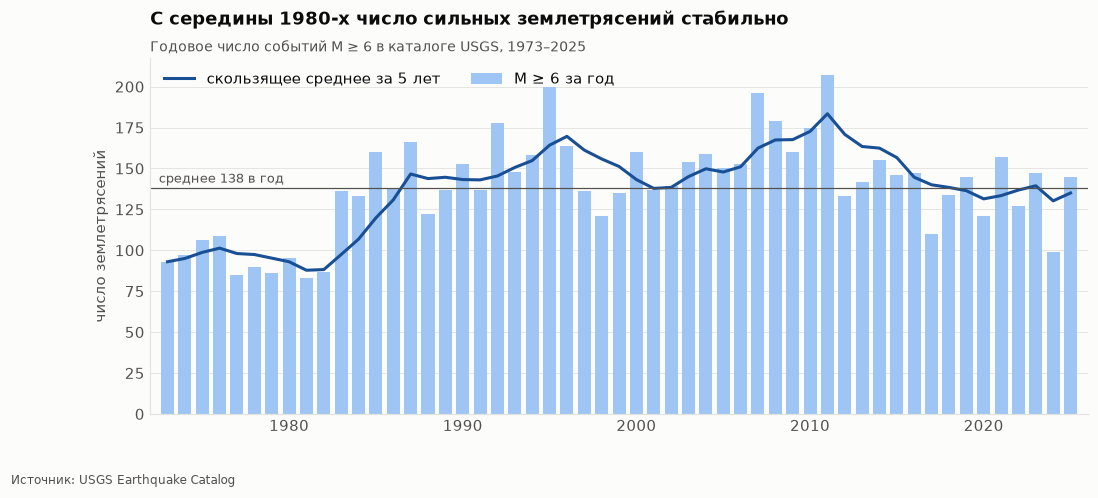

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(yearly["year"], yearly["n_m6"], width=0.75, color=plots.BLUE_RAMP[1], label="M ≥ 6 за год")
ax.plot(yearly["year"], yearly["n_m6_rolling5"], color=plots.BLUE_RAMP[5], label="скользящее среднее за 5 лет")
mean = yearly["n_m6"].mean()
ax.axhline(mean, color=plots.TEXT_MUTED, linewidth=0.8)
ax.text(yearly["year"].min() - 0.5, mean + 3, f"среднее {mean:.0f} в год", color=plots.TEXT_MUTED, fontsize=8.5)
ax.set_xlim(yearly["year"].min() - 1, yearly["year"].max() + 1)
ax.set_ylabel("число землетрясений")
ax.legend(loc="upper left", ncols=2)
ax.set_title("С середины 1980-х число сильных землетрясений стабильно")
plots.subtitle(ax, "Годовое число событий M ≥ 6 в каталоге USGS, 1973–2025")
plots.source_note(fig, "Источник: USGS Earthquake Catalog")
plots.save(fig, "02_yearly_m6")
plt.show()

## 2.3. Сейсмические зоны: ранжирование

In [6]:
show_sql("02_zone_activity")
zones = db.query("02_zone_activity")
zones

```sql
-- Активность сейсмических зон: годовая частота сильных событий и ранги
WITH span AS (
    SELECT MAX(year) - MIN(year) + 1 AS years FROM events
),
per_zone AS (
    SELECT
        z.zone_id,
        z.name                                         AS zone,
        z.boundary_type,
        COUNT(*)                                       AS n_events,
        SUM(e.mag >= 6.0)                              AS n_m6,
        SUM(e.mag >= 7.0)                              AS n_m7,
        MAX(e.mag)                                     AS max_mag,
        ROUND(AVG(e.depth_km), 1)                      AS mean_depth_km,
        ROUND(100.0 * SUM(e.depth_class = 'глубокофокусное') / COUNT(*), 1) AS deep_share_pct
    FROM events AS e
    JOIN zones  AS z USING (zone_id)
    GROUP BY z.zone_id
)
SELECT
    p.*,
    ROUND(1.0 * p.n_m7 / s.years, 3)                   AS m7_per_year,
    RANK() OVER (ORDER BY p.n_m7 DESC)                 AS rank_m7,
    ROUND(100.0 * p.n_events / SUM(p.n_events) OVER (), 1) AS share_of_catalog_pct
FROM per_zone AS p
CROSS JOIN span AS s
ORDER BY rank_m7;
```

,zone_id,zone,boundary_type,n_events,n_m6,n_m7,max_mag,mean_depth_km,deep_share_pct,m7_per_year,rank_m7,share_of_catalog_pct
0,7,"Тонга, Фиджи, Вануату, Кермадек",субдукция,50577,1422,137,8.2,157.2,21.3,2.585,1,17.6
1,5,Новая Гвинея и Соломоновы о-ва,субдукция,26860,851,89,8.1,57.4,1.0,1.679,2,9.3
2,1,"Япония, Курилы, Камчатка",субдукция,30785,758,76,9.1,55.6,3.3,1.434,3,10.7
3,8,"Анды (Чили, Перу, Эквадор)",субдукция,19670,607,75,8.8,80.8,1.5,1.415,4,6.8
4,4,Индонезия,субдукция,33203,723,73,9.1,82.4,4.6,1.377,5,11.6
5,99,Прочие (океанические хребты и др.),разные,47963,1035,55,8.1,21.5,0.0,1.038,6,16.7
6,9,Мексика и Центральная Америка,субдукция,10962,399,47,8.2,43.7,0.0,0.887,7,3.8
7,3,Филиппины и Тайвань,субдукция,17332,383,45,7.9,55.1,1.6,0.849,8,6.0
8,13,"Гималаи, Центральная Азия, Китай",коллизия,14168,292,38,7.9,48.1,0.0,0.717,9,4.9
9,2,Алеуты и Аляска,субдукция,9607,327,32,8.2,39.4,0.0,0.604,10,3.3


In [7]:
show_sql("03_strongest_per_zone")
db.query("03_strongest_per_zone").head(15)

```sql
-- Три сильнейших землетрясения каждой зоны (ROW_NUMBER по разделам)
WITH ranked AS (
    SELECT
        z.name AS zone,
        e.time_utc,
        e.mag,
        e.depth_km,
        e.place,
        ROW_NUMBER() OVER (PARTITION BY e.zone_id ORDER BY e.mag DESC, e.time_utc) AS rn
    FROM events AS e
    JOIN zones  AS z USING (zone_id)
    WHERE e.zone_id <> 99
)
SELECT zone, rn, SUBSTR(time_utc, 1, 10) AS date, mag, depth_km, place
FROM ranked
WHERE rn <= 3
ORDER BY zone, rn;
```

,zone,rn,date,mag,depth_km,place
0,Алеуты и Аляска,1,2021-07-29,8.2,35.000,"2021 Chignik, Alaska Earthquake"
1,Алеуты и Аляска,2,1986-05-07,8.0,33.000,"1986 Atka, Alaska Earthquake"
2,Алеуты и Аляска,3,1987-11-30,7.9,10.000,"200 km WSW of Yakutat, Alaska"
3,"Анды (Чили, Перу, Эквадор)",1,2010-02-27,8.8,22.900,"2010 Maule, Chile Earthquake"
4,"Анды (Чили, Перу, Эквадор)",2,2001-06-23,8.4,33.000,"6 km SSW of Atico, Peru"
5,"Анды (Чили, Перу, Эквадор)",3,2015-09-16,8.3,22.440,"48 km W of Illapel, Chile"
6,"Гималаи, Центральная Азия, Китай",1,2008-05-12,7.9,19.000,"58 km W of Tianpeng, China"
7,"Гималаи, Центральная Азия, Китай",2,2001-11-14,7.8,10.000,"Southern Qinghai, China"
8,"Гималаи, Центральная Азия, Китай",3,2015-04-25,7.8,8.220,"67 km NNE of Bharatpur, Nepal"
9,Запад США и Канады,1,1992-06-28,7.3,-0.097,"The 1992 Landers, California Earthquake"


## 2.4. Активность зон по десятилетиям

Сводная таблица строится в pandas (`pivot_table`) из результата SQL-агрегации.

In [8]:
zone_decade = db.query("""
    SELECT z.name AS zone, (e.year / 10) * 10 AS decade, COUNT(*) AS n_m6
    FROM events e JOIN zones z USING (zone_id)
    WHERE e.mag >= 6.0 AND e.zone_id <> 99
    GROUP BY zone, decade
""")
heat = (zone_decade.pivot_table(index="zone", columns="decade", values="n_m6", fill_value=0)
        .loc[lambda d: d.sum(axis=1).sort_values(ascending=False).index])
# 1970-е (с 1973) и 2020-е — неполные десятилетия, приводим к частоте за 10 лет
heat[1970] = (heat[1970] * 10 / 7).round()
heat[2020] = (heat[2020] * 10 / 6).round()
heat

decade,1970,1980,1990,2000,2010,2020
zone,,,,,,
"Тонга, Фиджи, Вануату, Кермадек",171.0,277.0,281.0,310.0,272.0,270.0
Новая Гвинея и Соломоновы о-ва,106.0,148.0,181.0,197.0,180.0,118.0
"Япония, Курилы, Камчатка",101.0,108.0,165.0,145.0,183.0,143.0
Индонезия,96.0,106.0,139.0,211.0,129.0,118.0
"Анды (Чили, Перу, Эквадор)",63.0,107.0,110.0,108.0,177.0,102.0
Мексика и Центральная Америка,46.0,58.0,104.0,79.0,84.0,70.0
Филиппины и Тайвань,66.0,65.0,88.0,63.0,61.0,100.0
Алеуты и Аляска,46.0,63.0,65.0,63.0,70.0,57.0
"Гималаи, Центральная Азия, Китай",64.0,50.0,68.0,59.0,47.0,38.0


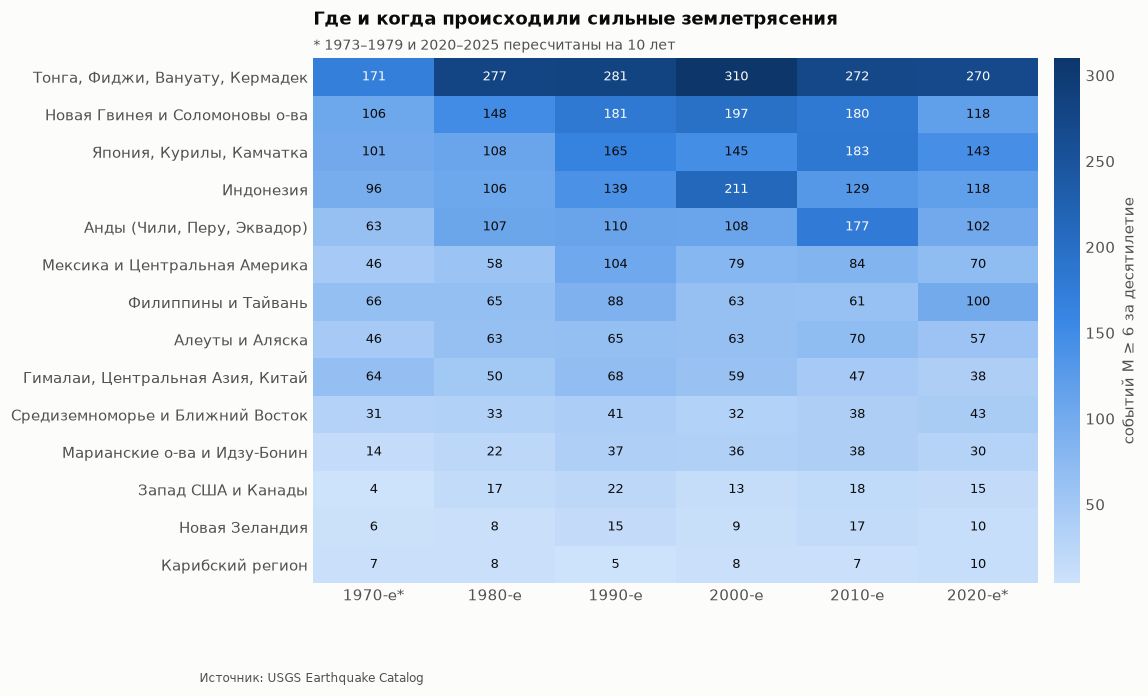

In [9]:
fig, ax = plt.subplots(figsize=(9, 6.2))
im = ax.imshow(heat.to_numpy(), cmap=plots.SEQUENTIAL, aspect="auto")
ax.set_xticks(range(heat.shape[1]), [f"{d}-е" + ("*" if d in (1970, 2020) else "") for d in heat.columns])
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
values = heat.to_numpy()
threshold = values.max() * 0.55
for (i, j), v in np.ndenumerate(values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
            color=plots.SURFACE if v > threshold else plots.TEXT)
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.outline.set_visible(False)
cbar.set_label("событий M ≥ 6 за десятилетие")
ax.set_title("Где и когда происходили сильные землетрясения")
plots.subtitle(ax, "* 1973–1979 и 2020–2025 пересчитаны на 10 лет")
plots.source_note(fig, "Источник: USGS Earthquake Catalog")
plots.save(fig, "03_zone_decade_heatmap")
plt.show()

## 2.5. Глубина очагов по зонам

In [10]:
show_sql("10_depth_profile")
depth = db.query("10_depth_profile").set_index("zone")
depth

```sql
-- Распределение глубин очагов по зонам (доли, %)
SELECT
    z.name AS zone,
    COUNT(*) AS n_events,
    ROUND(100.0 * AVG(e.depth_class = 'мелкофокусное'),   1) AS shallow_pct,
    ROUND(100.0 * AVG(e.depth_class = 'промежуточное'),   1) AS intermediate_pct,
    ROUND(100.0 * AVG(e.depth_class = 'глубокофокусное'), 1) AS deep_pct,
    MAX(e.depth_km) AS max_depth_km
FROM events AS e
JOIN zones  AS z USING (zone_id)
GROUP BY z.zone_id
ORDER BY deep_pct DESC;
```

,n_events,shallow_pct,intermediate_pct,deep_pct,max_depth_km
zone,,,,,
"Тонга, Фиджи, Вануату, Кермадек",50577,61.4,17.3,21.3,700.900
Марианские о-ва и Идзу-Бонин,11077,70.5,22.8,6.6,683.360
Индонезия,33203,67.6,27.9,4.6,675.500
"Япония, Курилы, Камчатка",30785,84.2,12.5,3.3,678.900
Филиппины и Тайвань,17332,79.8,18.6,1.6,678.000
"Анды (Чили, Перу, Эквадор)",19670,59.6,38.9,1.5,650.000
Новая Гвинея и Соломоновы о-ва,26860,74.8,24.2,1.0,631.800
Новая Зеландия,2209,74.6,24.6,0.9,588.400
Средиземноморье и Ближний Восток,8952,95.1,4.5,0.4,609.800


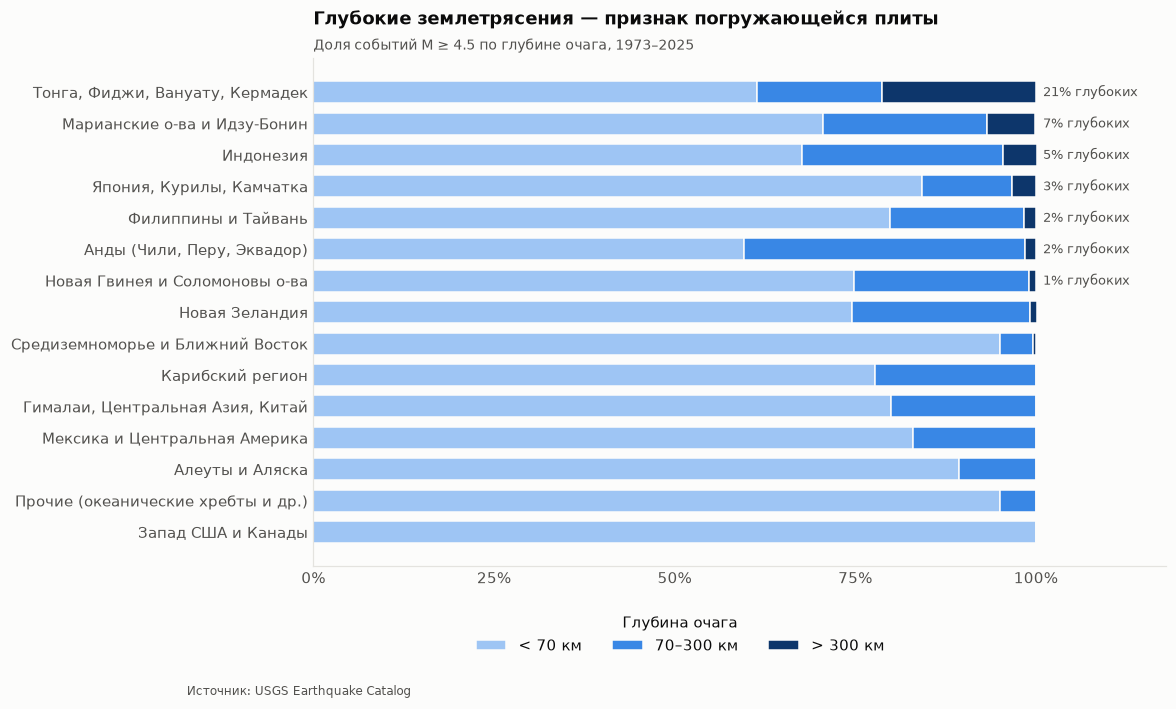

In [11]:
order = depth.sort_values(["deep_pct", "intermediate_pct"]).index
cols = {"shallow_pct": ("< 70 км", plots.BLUE_RAMP[1]),
        "intermediate_pct": ("70–300 км", plots.BLUE_RAMP[3]),
        "deep_pct": ("> 300 км", plots.BLUE_RAMP[6])}

fig, ax = plt.subplots(figsize=(10, 6))
left = np.zeros(len(order))
for col, (label, color) in cols.items():
    vals = depth.loc[order, col].to_numpy()
    ax.barh(order, vals, left=left, color=color, height=0.7, label=label,
            edgecolor=plots.SURFACE, linewidth=1)
    left += vals
for i, v in enumerate(depth.loc[order, "deep_pct"]):
    if v >= 1:
        ax.text(101, i, f"{v:.0f}% глубоких", va="center", fontsize=8.5, color=plots.TEXT_MUTED)
ax.set_xlim(0, 118)
ax.set_xticks(range(0, 101, 25), [f"{x}%" for x in range(0, 101, 25)])
ax.grid(axis="y", visible=False)
ax.legend(title="Глубина очага", loc="lower center", bbox_to_anchor=(0.43, -0.2), ncols=3)
ax.set_title("Глубокие землетрясения — признак погружающейся плиты")
plots.subtitle(ax, "Доля событий M ≥ 4.5 по глубине очага, 1973–2025")
plots.source_note(fig, "Источник: USGS Earthquake Catalog", y=-0.07)
plots.save(fig, "04_depth_profile")
plt.show()

В зоне Тонга–Кермадек каждое пятое событие происходит глубже 300 км: здесь самая быстрая
в мире субдукция (до 24 см/год), и холодная плита сохраняет хрупкость до глубин 700 км.
В коллизионных зонах (Средиземноморье, Гималаи) и на трансформной границе запада США
глубокофокусных событий практически нет.

## 2.6. Жертвы землетрясений по десятилетиям

In [12]:
show_sql("06_deaths_by_decade")
deaths = db.query("06_deaths_by_decade")
deaths

```sql
-- Гибель людей при землетрясениях по десятилетиям, с накопленным итогом
-- и долей самого смертоносного события десятилетия
WITH by_decade AS (
    SELECT
        (year / 10) * 10                    AS decade,
        COUNT(*)                            AS n_significant,
        SUM(COALESCE(deaths, 0))            AS deaths,
        MAX(COALESCE(deaths, 0))            AS worst_event_deaths
    FROM significant
    GROUP BY decade
)
SELECT
    decade,
    n_significant,
    deaths,
    ROUND(100.0 * worst_event_deaths / NULLIF(deaths, 0), 1) AS worst_event_share_pct,
    SUM(deaths) OVER (ORDER BY decade)                       AS deaths_cumulative
FROM by_decade
ORDER BY decade;
```

,decade,n_significant,deaths,worst_event_share_pct,deaths_cumulative
0,1900,242,148822,53.8,148822
1,1910,207,50767,59.1,199589
2,1920,239,419601,56.1,619190
3,1930,248,180257,33.3,799447
4,1940,188,161880,68.0,961327
5,1950,241,24118,41.5,985445
6,1960,299,59133,22.2,1044578
7,1970,297,440739,55.1,1485317
8,1980,324,67132,37.2,1552449
9,1990,335,107886,37.1,1660335


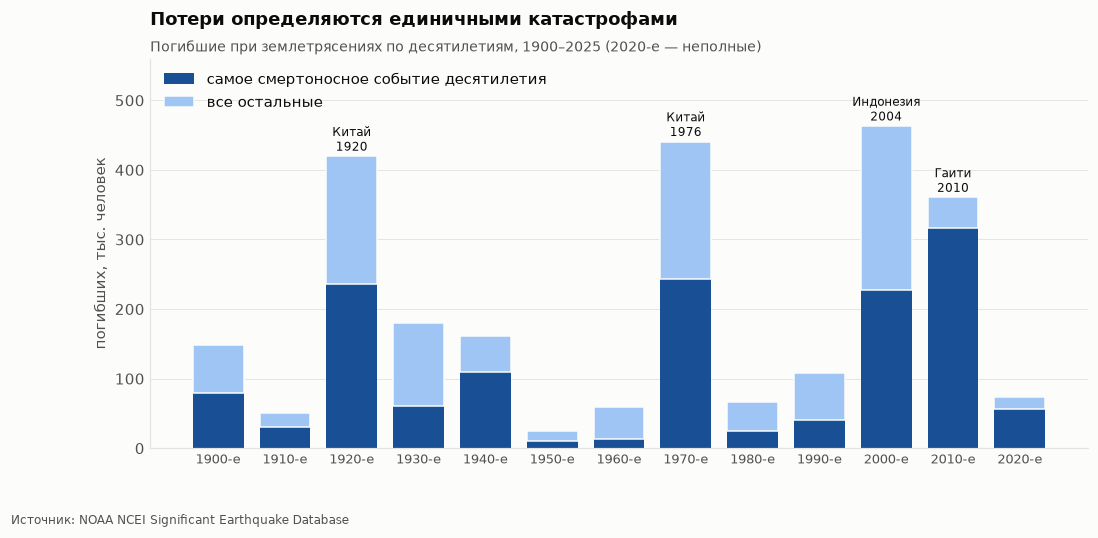

In [13]:
worst = db.query("""
    WITH ranked AS (
        SELECT (year / 10) * 10 AS decade, year, country, deaths,
               ROW_NUMBER() OVER (PARTITION BY (year / 10) * 10 ORDER BY deaths DESC) AS rn
        FROM significant WHERE deaths IS NOT NULL
    )
    SELECT decade, year, country, deaths FROM ranked WHERE rn = 1
""").set_index("decade")

fig, ax = plt.subplots(figsize=(11, 4.6))
x = deaths["decade"].to_numpy()
other = deaths["deaths"] - worst.loc[x, "deaths"].to_numpy()
ax.bar(x, worst.loc[x, "deaths"] / 1e3, width=7.6, color=plots.BLUE_RAMP[5], label="самое смертоносное событие десятилетия")
ax.bar(x, other / 1e3, bottom=worst.loc[x, "deaths"] / 1e3, width=7.6, color=plots.BLUE_RAMP[1],
       label="все остальные", edgecolor=plots.SURFACE, linewidth=1)
for d in x:
    w = worst.loc[d]
    if w["deaths"] > 150_000:
        ax.text(d, deaths.set_index("decade").loc[d, "deaths"] / 1e3 + 8,
                f"{plots.COUNTRY_RU.get(w['country'], w['country'])}\n{w['year']}",
                ha="center", fontsize=8, color=plots.TEXT)
ax.set_xticks(x, [f"{d}-е" for d in x], fontsize=8.5)
ax.set_ylabel("погибших, тыс. человек")
ax.set_ylim(0, 560)
ax.legend(loc="upper left")
ax.set_title("Потери определяются единичными катастрофами")
plots.subtitle(ax, "Погибшие при землетрясениях по десятилетиям, 1900–2025 (2020-е — неполные)")
plots.source_note(fig, "Источник: NOAA NCEI Significant Earthquake Database")
plots.save(fig, "05_deaths_by_decade")
plt.show()

В 2010-х одно землетрясение на Гаити дало 88% всех погибших за десятилетие. Ряд потерь
не показывает тренда — он управляется редкими событиями в плотно заселённых и уязвимых районах.
Это мотивирует следующий шаг: отделить **опасность** (частоту и силу землетрясений, ноутбук 3)
от **уязвимости** (ноутбук 4).

## 2.7. Межсобытийные интервалы (параметризованный запрос)

In [14]:
show_sql("05_inter_event_m7")
gaps = db.query("05_inter_event_m7", {"min_mag": 7.0})
gaps["days_since_prev"].describe().round(1)

```sql
-- Интервалы (в сутках) между последовательными землетрясениями M ≥ :min_mag
SELECT
    event_id,
    time_utc,
    mag,
    zone_id,
    julianday(time_utc) - LAG(julianday(time_utc)) OVER (ORDER BY time_utc) AS days_since_prev
FROM events
WHERE mag >= :min_mag
ORDER BY time_utc;
```

count    728.0
mean      26.5
std       28.6
min        0.0
25%        7.1
50%       16.7
75%       35.4
max      176.8
Name: days_since_prev, dtype: float64